In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [2]:
df = pd.read_csv("data.csv")

In [3]:
df.head()

,CPU_Model,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU,Integrated_GPU_Score,...,GPU_Cores,GPU_Compute_Type,GPU_Memory_Bus_Bit,RAM_GB,RAM_DDR,RAM_Speed_MHz,Storage_Type,Storage_Read_MBps,Benchmark_Score,Performance_Tier
0,Ryzen 5 3600,3,6,12,3.70,4.19,33,63,No Integrated GPU,0,...,0,No Dedicated GPU,0,4,DDR5,5806,HDD,121,54,Entry Level
1,i5-2400,2,4,4,3.00,3.31,5,99,Intel HD 2000,307,...,1758,Stream,131,4,DDR4,3198,NVMe,3675,73,Mid Range
2,i5-12400,12,6,12,2.48,4.51,17,67,Intel UHD 730,1236,...,1792,Stream,126,64,DDR3,1680,SATA SSD,544,100,Enthusiast
3,i5-2400,2,4,4,2.95,3.50,7,91,Intel HD 2000,325,...,1704,Stream,130,64,DDR4,2573,NVMe,3394,100,Enthusiast
4,i5-3470,3,4,4,3.13,3.49,5,80,Intel HD 2500,410,...,3601,CUDA,186,64,DDR5,4968,NVMe,3606,100,Enthusiast


In [4]:
df.tail()

,CPU_Model,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU,Integrated_GPU_Score,...,GPU_Cores,GPU_Compute_Type,GPU_Memory_Bus_Bit,RAM_GB,RAM_DDR,RAM_Speed_MHz,Storage_Type,Storage_Read_MBps,Benchmark_Score,Performance_Tier
995,i5-12400,12,6,12,2.31,4.41,19,65,Intel UHD 730,1202,...,655,CUDA,131,32,DDR4,2376,HDD,123,100,Enthusiast
996,Ryzen 5 5600G,5,6,12,4.06,4.54,16,64,Radeon Vega 7,1678,...,504,Stream,129,32,DDR3,1675,SATA SSD,551,100,Enthusiast
997,i5-12400,12,6,12,2.43,4.50,18,68,Intel UHD 730,1233,...,897,CUDA,132,32,DDR5,5442,NVMe,3470,100,Enthusiast
998,i5-12400,12,6,12,2.56,4.29,18,66,Intel UHD 730,1228,...,920,CUDA,124,4,DDR5,5367,NVMe,3458,87,High End
999,i5-3470,3,4,4,3.27,3.42,5,80,Intel HD 2500,407,...,3416,CUDA,183,4,DDR4,2708,NVMe,3369,80,High End


In [5]:
df.sample(5)

,CPU_Model,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU,Integrated_GPU_Score,...,GPU_Cores,GPU_Compute_Type,GPU_Memory_Bus_Bit,RAM_GB,RAM_DDR,RAM_Speed_MHz,Storage_Type,Storage_Read_MBps,Benchmark_Score,Performance_Tier
880,i5-12400,12,6,12,2.42,4.34,19,66,Intel UHD 730,1212,...,921,CUDA,127,8,DDR5,5855,NVMe,3372,95,Enthusiast
63,i5-3470,3,4,4,3.34,3.46,7,76,Intel HD 2500,416,...,3436,CUDA,186,32,DDR4,2727,NVMe,3439,100,Enthusiast
800,i5-12400,12,6,12,2.36,4.33,18,62,Intel UHD 730,1217,...,505,Stream,132,64,DDR4,2385,SATA SSD,539,100,Enthusiast
405,i7-3770,3,4,8,3.22,3.95,9,79,Intel HD 4000,652,...,0,No Dedicated GPU,0,16,DDR3,1324,HDD,120,49,Entry Level
452,Ryzen 5 5600G,5,6,12,3.80,4.31,17,67,Radeon Vega 7,1550,...,497,Stream,125,64,DDR3,1630,SATA SSD,575,100,Enthusiast


In [6]:
df.shape

(1000, 24)

In [7]:
df.columns

Index(['CPU_Model', 'CPU_Generation', 'CPU_Cores', 'CPU_Threads',
       'CPU_Base_GHz', 'CPU_Boost_GHz', 'CPU_Cache_MB', 'CPU_TDP_W',
       'Integrated_GPU', 'Integrated_GPU_Score', 'Dedicated_GPU',
       'Has_Dedicated_GPU', 'Dedicated_GPU_Score', 'GPU_VRAM_GB', 'GPU_Cores',
       'GPU_Compute_Type', 'GPU_Memory_Bus_Bit', 'RAM_GB', 'RAM_DDR',
       'RAM_Speed_MHz', 'Storage_Type', 'Storage_Read_MBps', 'Benchmark_Score',
       'Performance_Tier'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CPU_Model             1000 non-null   str    
 1   CPU_Generation        1000 non-null   int64  
 2   CPU_Cores             1000 non-null   int64  
 3   CPU_Threads           1000 non-null   int64  
 4   CPU_Base_GHz          1000 non-null   float64
 5   CPU_Boost_GHz         1000 non-null   float64
 6   CPU_Cache_MB          1000 non-null   int64  
 7   CPU_TDP_W             1000 non-null   int64  
 8   Integrated_GPU        1000 non-null   str    
 9   Integrated_GPU_Score  1000 non-null   int64  
 10  Dedicated_GPU         1000 non-null   str    
 11  Has_Dedicated_GPU     1000 non-null   int64  
 12  Dedicated_GPU_Score   1000 non-null   int64  
 13  GPU_VRAM_GB           1000 non-null   int64  
 14  GPU_Cores             1000 non-null   int64  
 15  GPU_Compute_Type      1000 non-nu

In [9]:
df.describe()

,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU_Score,Has_Dedicated_GPU,Dedicated_GPU_Score,GPU_VRAM_GB,GPU_Cores,GPU_Memory_Bus_Bit,RAM_GB,RAM_Speed_MHz,Storage_Read_MBps,Benchmark_Score
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.00000,1000.000000
mean,4.530000,5.114000,9.052000,3.31100,4.008850,16.249000,72.986000,626.601000,0.844000,6885.407000,4.316000,1012.369000,113.708000,24.124000,2980.47200,1444.82200,82.721000
std,3.286016,0.993978,3.538618,0.44197,0.382979,10.284881,10.708617,558.381848,0.363037,5567.993308,3.455443,967.833557,52.160804,21.546249,1526.45721,1507.65051,19.364301
min,2.000000,4.000000,4.000000,2.30000,3.200000,5.000000,62.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,1267.00000,114.00000,25.000000
25%,3.000000,4.000000,4.000000,3.07750,3.690000,7.000000,65.000000,1.000000,1.000000,3590.750000,2.000000,515.750000,123.000000,8.000000,1607.00000,124.00000,69.750000
50%,3.000000,6.000000,12.000000,3.37000,4.080000,15.000000,68.000000,429.000000,1.000000,4215.500000,3.000000,651.000000,127.000000,16.000000,2562.50000,554.00000,89.000000
75%,5.000000,6.000000,12.000000,3.63000,4.310000,31.000000,78.000000,1188.000000,1.000000,8178.500000,5.000000,939.250000,132.000000,32.000000,4636.25000,3433.50000,100.000000
max,12.000000,6.000000,12.000000,4.10000,4.600000,33.000000,99.000000,1680.000000,1.000000,17806.000000,13.000000,3763.000000,201.000000,64.000000,5879.00000,3675.00000,100.000000


In [10]:
df.isnull().sum()

CPU_Model               0
CPU_Generation          0
CPU_Cores               0
CPU_Threads             0
CPU_Base_GHz            0
CPU_Boost_GHz           0
CPU_Cache_MB            0
CPU_TDP_W               0
Integrated_GPU          0
Integrated_GPU_Score    0
Dedicated_GPU           0
Has_Dedicated_GPU       0
Dedicated_GPU_Score     0
GPU_VRAM_GB             0
GPU_Cores               0
GPU_Compute_Type        0
GPU_Memory_Bus_Bit      0
RAM_GB                  0
RAM_DDR                 0
RAM_Speed_MHz           0
Storage_Type            0
Storage_Read_MBps       0
Benchmark_Score         0
Performance_Tier        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["RAM_DDR"].unique()

<StringArray>
['DDR5', 'DDR4', 'DDR3']
Length: 3, dtype: str

In [13]:
df["Storage_Type"].unique()

<StringArray>
['HDD', 'NVMe', 'SATA SSD']
Length: 3, dtype: str

In [14]:
df["Benchmark_Score"].describe()

count    1000.000000
mean       82.721000
std        19.364301
min        25.000000
25%        69.750000
50%        89.000000
75%       100.000000
max       100.000000
Name: Benchmark_Score, dtype: float64

In [15]:
df["Benchmark_Score"].describe()

count    1000.000000
mean       82.721000
std        19.364301
min        25.000000
25%        69.750000
50%        89.000000
75%       100.000000
max       100.000000
Name: Benchmark_Score, dtype: float64

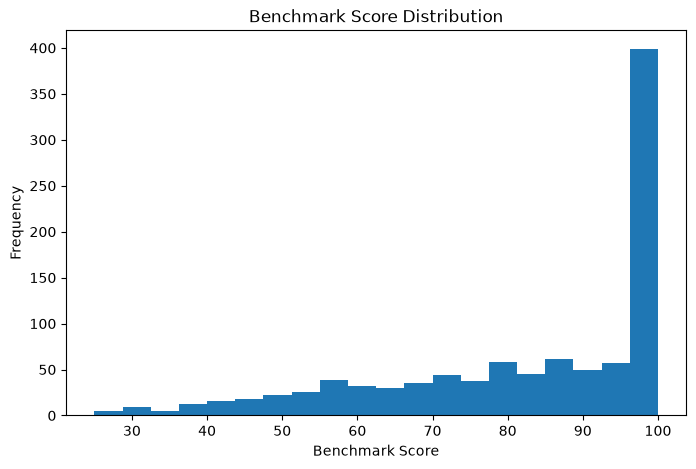

In [16]:
plt.figure(figsize=(8,5))
plt.hist(df["Benchmark_Score"], bins=20)
plt.title("Benchmark Score Distribution")
plt.xlabel("Benchmark Score")
plt.ylabel("Frequency")
plt.show()

In [17]:
df["Performance_Tier"].value_counts()

Performance_Tier
Enthusiast     495
High End       205
Mid Range      186
Entry Level    104
Low End         10
Name: count, dtype: int64

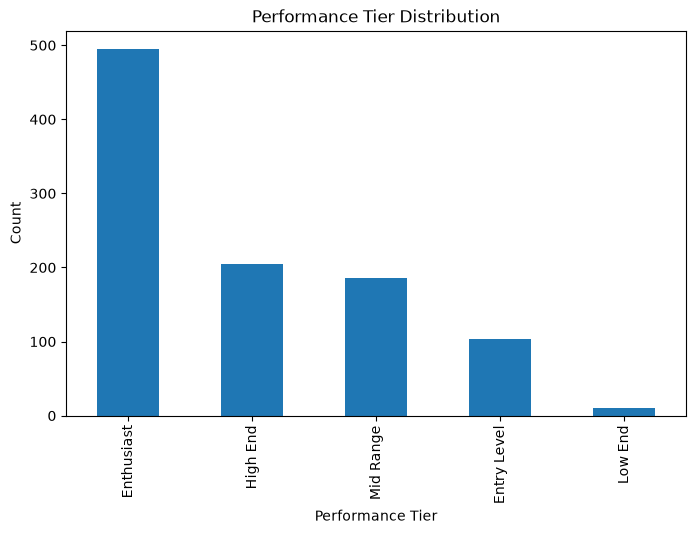

In [18]:
df["Performance_Tier"].value_counts().plot(kind="bar", figsize=(8,5))

plt.title("Performance Tier Distribution")
plt.xlabel("Performance Tier")
plt.ylabel("Count")

plt.show()

In [19]:
df["RAM_GB"].value_counts()

RAM_GB
4     215
32    206
8     202
16    189
64    188
Name: count, dtype: int64

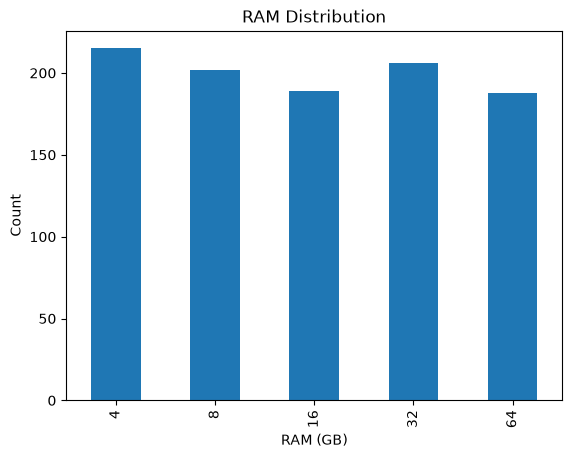

In [20]:
df["RAM_GB"].value_counts().sort_index().plot(kind="bar")

plt.title("RAM Distribution")
plt.xlabel("RAM (GB)")
plt.ylabel("Count")

plt.show()

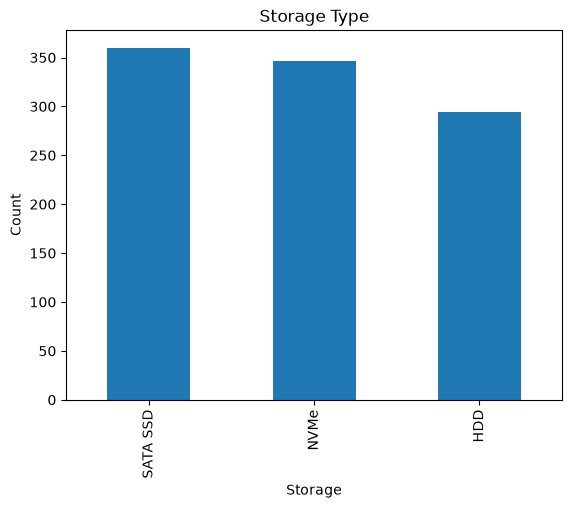

In [21]:
df["Storage_Type"].value_counts().plot(kind="bar")

plt.title("Storage Type")
plt.xlabel("Storage")
plt.ylabel("Count")

plt.show()

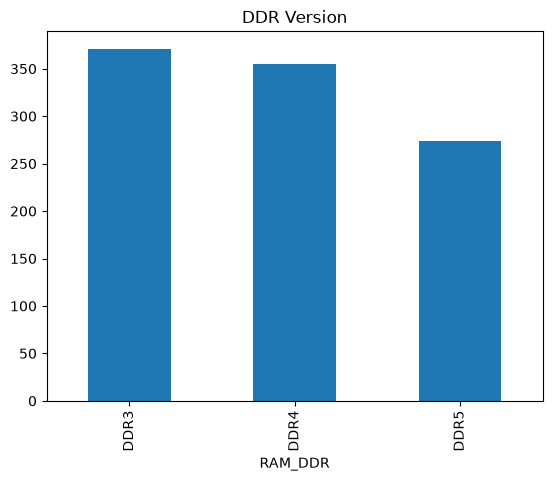

In [22]:
df["RAM_DDR"].value_counts().plot(kind="bar")

plt.title("DDR Version")

plt.show()

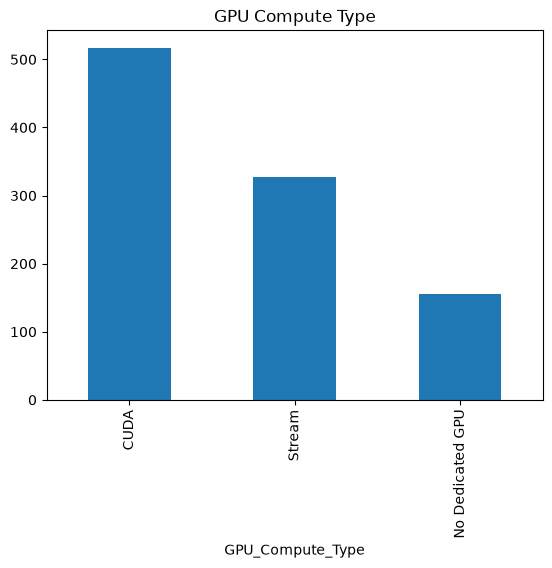

In [23]:
df["GPU_Compute_Type"].value_counts().plot(kind="bar")

plt.title("GPU Compute Type")

plt.show()

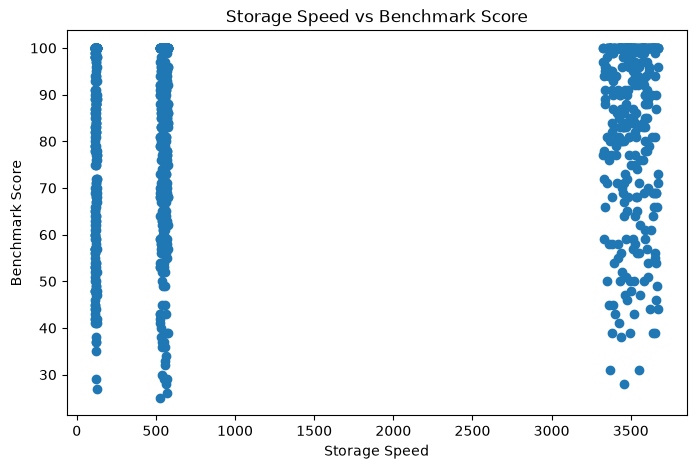

In [24]:
plt.figure(figsize=(8,5))

plt.scatter(df["Storage_Read_MBps"],
            df["Benchmark_Score"])

plt.xlabel("Storage Speed")

plt.ylabel("Benchmark Score")

plt.title("Storage Speed vs Benchmark Score")

plt.show()

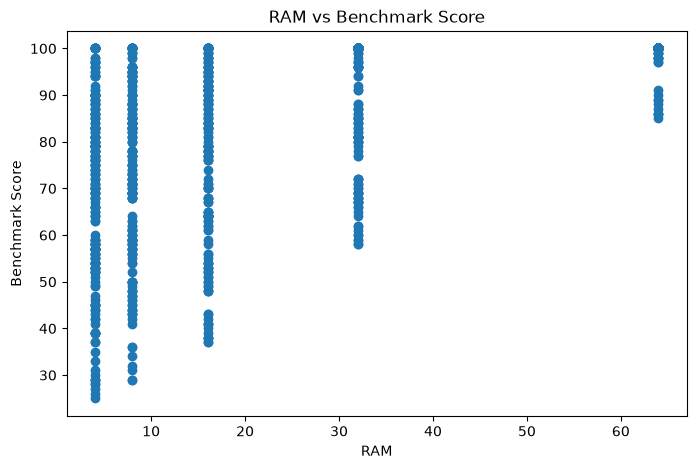

In [25]:
plt.figure(figsize=(8,5))

plt.scatter(df["RAM_GB"],
            df["Benchmark_Score"])

plt.xlabel("RAM")

plt.ylabel("Benchmark Score")

plt.title("RAM vs Benchmark Score")

plt.show()

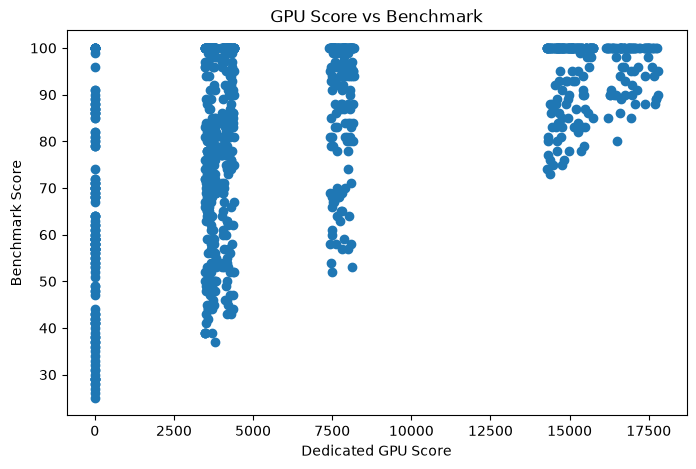

In [26]:
plt.figure(figsize=(8,5))

plt.scatter(df["Dedicated_GPU_Score"],
            df["Benchmark_Score"])

plt.xlabel("Dedicated GPU Score")

plt.ylabel("Benchmark Score")

plt.title("GPU Score vs Benchmark")

plt.show()

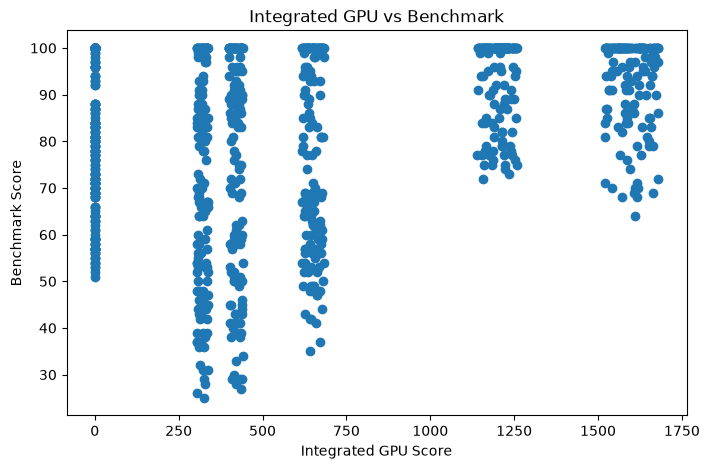

In [27]:
plt.figure(figsize=(8,5))

plt.scatter(df["Integrated_GPU_Score"],
            df["Benchmark_Score"])

plt.xlabel("Integrated GPU Score")

plt.ylabel("Benchmark Score")

plt.title("Integrated GPU vs Benchmark")

plt.show()

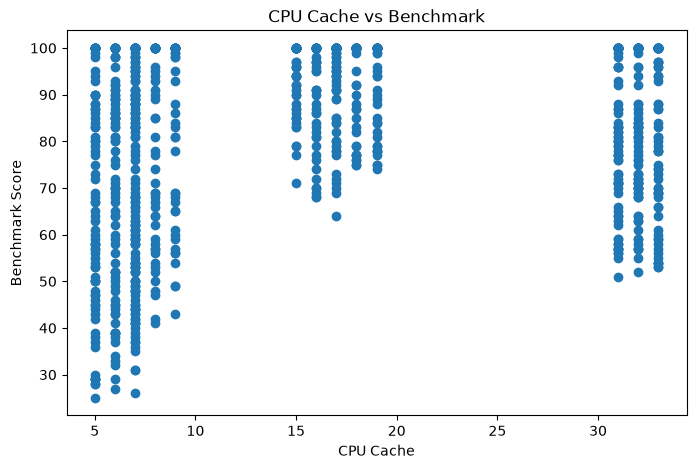

In [28]:
plt.figure(figsize=(8,5))

plt.scatter(df["CPU_Cache_MB"],
            df["Benchmark_Score"])

plt.xlabel("CPU Cache")

plt.ylabel("Benchmark Score")

plt.title("CPU Cache vs Benchmark")

plt.show()

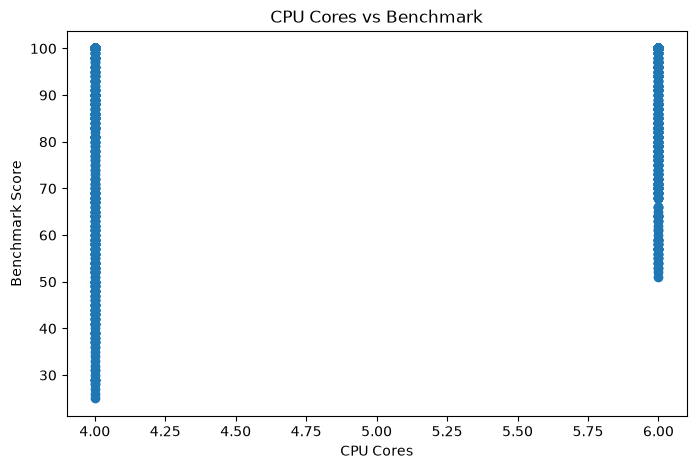

In [29]:
plt.figure(figsize=(8,5))

plt.scatter(df["CPU_Cores"],
            df["Benchmark_Score"])

plt.xlabel("CPU Cores")

plt.ylabel("Benchmark Score")

plt.title("CPU Cores vs Benchmark")

plt.show()

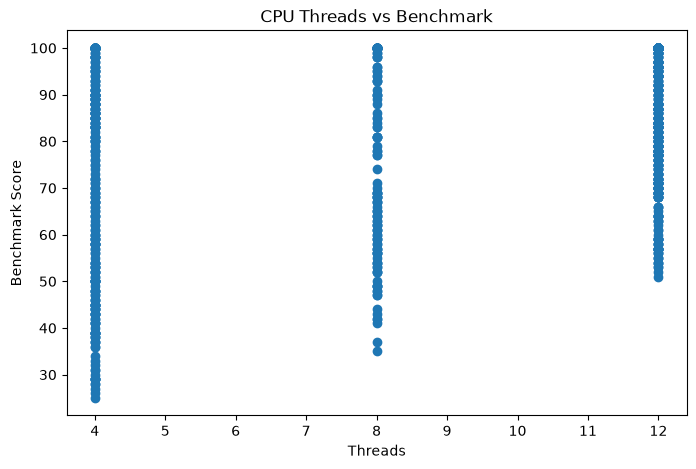

In [30]:
plt.figure(figsize=(8,5))

plt.scatter(df["CPU_Threads"],
            df["Benchmark_Score"])

plt.xlabel("Threads")

plt.ylabel("Benchmark Score")

plt.title("CPU Threads vs Benchmark")

plt.show()

In [31]:
numeric_df = df.select_dtypes(include=["int64","float64"])

In [32]:
corr = numeric_df.corr()

corr

,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU_Score,Has_Dedicated_GPU,Dedicated_GPU_Score,GPU_VRAM_GB,GPU_Cores,GPU_Memory_Bus_Bit,RAM_GB,RAM_Speed_MHz,Storage_Read_MBps,Benchmark_Score
CPU_Generation,1.000000,0.503095,0.486767,-0.628982,0.601081,0.112552,-0.460881,0.613149,0.180138,-0.001370,0.007363,-0.026434,0.135594,0.008685,0.006354,0.060247,0.311838
CPU_Cores,0.503095,1.000000,0.934624,0.162385,0.862393,0.831572,-0.821782,0.258283,-0.011695,-0.207890,-0.185948,-0.217119,-0.071179,0.004013,-0.040323,0.064958,0.354829
CPU_Threads,0.486767,0.934624,1.000000,0.215046,0.919451,0.797793,-0.859400,0.296743,0.006321,-0.203084,-0.170642,-0.200126,-0.042718,-0.002343,-0.013323,0.033227,0.357282
CPU_Base_GHz,-0.628982,0.162385,0.215046,1.000000,0.123460,0.284836,-0.212604,-0.080324,-0.166659,-0.134741,-0.101887,-0.107790,-0.153912,-0.025409,-0.071185,0.016526,-0.009667
CPU_Boost_GHz,0.601081,0.862393,0.919451,0.123460,1.000000,0.622560,-0.852239,0.471757,0.047378,-0.143551,-0.109616,-0.146431,0.004261,-0.002676,-0.030399,0.056203,0.388205
CPU_Cache_MB,0.112552,0.831572,0.797793,0.284836,0.622560,1.000000,-0.701825,-0.293558,-0.106474,-0.208613,-0.200930,-0.192874,-0.138600,0.000529,0.024487,-0.002145,0.201113
CPU_TDP_W,-0.460881,-0.821782,-0.859400,-0.212604,-0.852239,-0.701825,1.000000,-0.268900,0.012569,0.124783,0.094558,0.105955,0.031112,0.007713,0.010050,-0.034013,-0.344901
Integrated_GPU_Score,0.613149,0.258283,0.296743,-0.080324,0.471757,-0.293558,-0.268900,1.000000,0.159995,0.000184,0.036807,-0.032014,0.124416,0.002766,-0.101691,0.094494,0.278174
Has_Dedicated_GPU,0.180138,-0.011695,0.006321,-0.166659,0.047378,-0.106474,0.012569,0.159995,1.000000,0.531882,0.488587,0.449766,0.935514,0.049057,0.061809,0.234743,0.442761
Dedicated_GPU_Score,-0.001370,-0.207890,-0.203084,-0.134741,-0.143551,-0.208613,0.124783,0.000184,0.531882,1.000000,0.935146,0.917884,0.673563,0.001539,0.027347,0.049378,0.512902


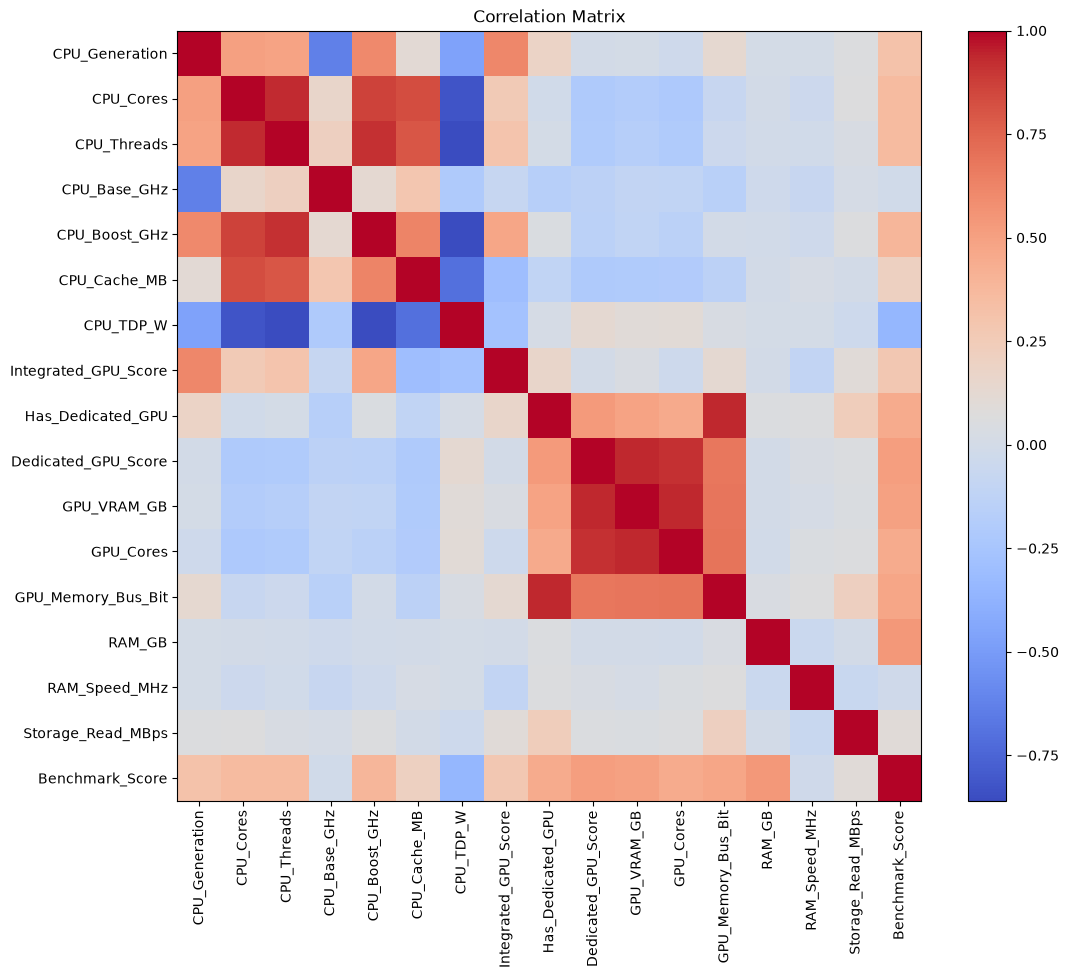

In [33]:
plt.figure(figsize=(12,10))

plt.imshow(corr, cmap="coolwarm", aspect="auto")

plt.xticks(range(len(corr.columns)),
           corr.columns,
           rotation=90)

plt.yticks(range(len(corr.columns)),
           corr.columns)

plt.colorbar()

plt.title("Correlation Matrix")

plt.show()

In [34]:
corr["Benchmark_Score"].sort_values(ascending=False)

Benchmark_Score         1.000000
RAM_GB                  0.536547
Dedicated_GPU_Score     0.512902
GPU_VRAM_GB             0.491884
GPU_Memory_Bus_Bit      0.474120
Has_Dedicated_GPU       0.442761
GPU_Cores               0.441380
CPU_Boost_GHz           0.388205
CPU_Threads             0.357282
CPU_Cores               0.354829
CPU_Generation          0.311838
Integrated_GPU_Score    0.278174
CPU_Cache_MB            0.201113
Storage_Read_MBps       0.094202
CPU_Base_GHz           -0.009667
RAM_Speed_MHz          -0.019804
CPU_TDP_W              -0.344901
Name: Benchmark_Score, dtype: float64

In [35]:
X = df.drop(columns=["Benchmark_Score", "Performance_Tier"])
y = df["Benchmark_Score"]

In [36]:
X.head()

,CPU_Model,CPU_Generation,CPU_Cores,CPU_Threads,CPU_Base_GHz,CPU_Boost_GHz,CPU_Cache_MB,CPU_TDP_W,Integrated_GPU,Integrated_GPU_Score,...,Dedicated_GPU_Score,GPU_VRAM_GB,GPU_Cores,GPU_Compute_Type,GPU_Memory_Bus_Bit,RAM_GB,RAM_DDR,RAM_Speed_MHz,Storage_Type,Storage_Read_MBps
0,Ryzen 5 3600,3,6,12,3.70,4.19,33,63,No Integrated GPU,0,...,0,0,0,No Dedicated GPU,0,4,DDR5,5806,HDD,121
1,i5-2400,2,4,4,3.00,3.31,5,99,Intel HD 2000,307,...,14395,8,1758,Stream,131,4,DDR4,3198,NVMe,3675
2,i5-12400,12,6,12,2.48,4.51,17,67,Intel UHD 730,1236,...,14719,7,1792,Stream,126,64,DDR3,1680,SATA SSD,544
3,i5-2400,2,4,4,2.95,3.50,7,91,Intel HD 2000,325,...,15107,7,1704,Stream,130,64,DDR4,2573,NVMe,3394
4,i5-3470,3,4,4,3.13,3.49,5,80,Intel HD 2500,410,...,16252,13,3601,CUDA,186,64,DDR5,4968,NVMe,3606


In [37]:
y.head()

0     54
1     73
2    100
3    100
4    100
Name: Benchmark_Score, dtype: int64

In [38]:
numerical_columns = X.select_dtypes(include=["int64","float64"]).columns

numerical_columns

Index(['CPU_Generation', 'CPU_Cores', 'CPU_Threads', 'CPU_Base_GHz',
       'CPU_Boost_GHz', 'CPU_Cache_MB', 'CPU_TDP_W', 'Integrated_GPU_Score',
       'Has_Dedicated_GPU', 'Dedicated_GPU_Score', 'GPU_VRAM_GB', 'GPU_Cores',
       'GPU_Memory_Bus_Bit', 'RAM_GB', 'RAM_Speed_MHz', 'Storage_Read_MBps'],
      dtype='str')

In [39]:
categorical_columns = X.select_dtypes(include=["object"]).columns

categorical_columns

C:\Users\dell\AppData\Local\Temp\ipykernel_65896\3973694625.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns


Index(['CPU_Model', 'Integrated_GPU', 'Dedicated_GPU', 'GPU_Compute_Type',
       'RAM_DDR', 'Storage_Type'],
      dtype='str')

In [40]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore")

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", encoder, categorical_columns)
    ],
    remainder="passthrough"
)

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [43]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 22)
(200, 22)
(800,)
(200,)


In [44]:
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [45]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=200,
        learning_rate=0.1,
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

xgb_prediction = xgb_model.predict(X_test)

In [46]:
print("XGBoost")

print("MAE :", mean_absolute_error(y_test, xgb_prediction))
print("MSE :", mean_squared_error(y_test, xgb_prediction))
print("RMSE:", mean_squared_error(y_test, xgb_prediction) ** 0.5)
print("R2 :", r2_score(y_test, xgb_prediction))

XGBoost
MAE : 2.2545905113220215
MSE : 12.740671157836914
RMSE: 3.5694076760489146
R2 : 0.9647975564002991


In [47]:
prediction = xgb_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": prediction
})

comparison.head(20)

,Actual,Predicted
521,80,76.636520
737,100,100.008720
740,57,59.927605
660,90,92.716904
411,58,57.206173
678,58,57.182930
626,100,99.667915
513,36,31.427483
859,100,99.832184
136,80,86.131393


In [48]:
comparison["Error"] = abs(comparison["Actual"] - comparison["Predicted"])

comparison.head(20)

,Actual,Predicted,Error
521,80,76.636520,3.363480
737,100,100.008720,0.008720
740,57,59.927605,2.927605
660,90,92.716904,2.716904
411,58,57.206173,0.793827
678,58,57.182930,0.817070
626,100,99.667915,0.332085
513,36,31.427483,4.572517
859,100,99.832184,0.167816
136,80,86.131393,6.131393


In [49]:
comparison.sort_values("Error", ascending=False).head(10)

,Actual,Predicted,Error
298,100,81.892700,18.107300
527,100,82.749054,17.250946
260,67,80.283974,13.283974
254,85,95.584732,10.584732
25,81,90.990440,9.990440
55,70,79.693344,9.693344
866,94,85.338684,8.661316
439,78,86.147026,8.147026
23,42,34.930683,7.069317
811,83,89.808792,6.808792


In [50]:
comparison["Error"].mean()

np.float64(2.2545903015136717)

In [51]:
import matplotlib.pyplot as plt

importance = xgb_model.named_steps["model"].feature_importances_

feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values("Importance", ascending=False)

print(importance_df.head(20))

                            Feature  Importance
28             remainder__CPU_Cores    0.412402
14         cat__Dedicated_GPU_NoGPU    0.149790
40                remainder__RAM_GB    0.104084
36   remainder__Dedicated_GPU_Score    0.095038
37           remainder__GPU_VRAM_GB    0.040761
27        remainder__CPU_Generation    0.040651
17       cat__Dedicated_GPU_RX 6600    0.028348
32          remainder__CPU_Cache_MB    0.024672
12      cat__Dedicated_GPU_GTX 1650    0.024122
29           remainder__CPU_Threads    0.017495
0       cat__CPU_Model_Ryzen 5 3600    0.010865
31         remainder__CPU_Boost_GHz    0.010591
5            cat__CPU_Model_i7-3770    0.008293
13    cat__Dedicated_GPU_GTX 750 Ti    0.006127
16        cat__Dedicated_GPU_RX 550    0.005311
38             remainder__GPU_Cores    0.004233
34  remainder__Integrated_GPU_Score    0.003578
33             remainder__CPU_TDP_W    0.003245
1      cat__CPU_Model_Ryzen 5 5600G    0.003118
4            cat__CPU_Model_i5-3470    0

In [52]:
import joblib

joblib.dump(xgb_model, "benchmark_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully
